# MarineGuard AI | Model Evaluation and Inference Diagnostics

**Scope.** Evaluate the saved YOLO12n and YOLO26n checkpoints for underwater Net (class 0) and Rope (class 1) detection. This notebook covers qualitative predictions, validation performance, input-resolution comparison, confidence filtering, and external testing. **No model training is performed.**

**Evaluation approach.** Quantitative metrics use the prepared YOLO validation and external TrashCan test splits; uploaded images provide qualitative examples only. We retain the original checkpoints and report both successful detections and failure cases.

**Interpretation limits.** The original validation split contains only **7 Net instances** (and 71 Rope instances), making its Net metrics unstable. Uploaded screenshots and images from the prepared dataset are not substitutes for an independently labeled test set. The original split does not establish generalization across locations or capture devices.

## 1. Environment and data access

Install Ultralytics and mount Drive to access the saved checkpoints, dataset configuration, and exported results.

In [ ]:
# Install inference dependencies and mount the experiment artifacts.
!pip -q install ultralytics

from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 2. Restore the selected checkpoint

Load the original YOLO26n `best.pt` and verify the expected class mapping (`Net`, `Rope`). This checkpoint is reused throughout the evaluation.

In [ ]:
# Restore the selected YOLO26n checkpoint from the original finalist run.
from pathlib import Path
from ultralytics import YOLO

MODEL_PATH = Path(
    "/content/drive/MyDrive/MarineGuard_Model_Selection/"
    "budget20_30_v1/runs_budget20_30_v1/"
    "final/yolo26n/weights/best.pt"
)

assert MODEL_PATH.exists(), "Model checkpoint not found!"

model = YOLO(str(MODEL_PATH))

print("Model loaded successfully!")
print("Classes:", model.names)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Model loaded successfully!
Classes: {0: 'Net', 1: 'Rope'}


## 3. Single-image inference and confidence sensitivity

Inspect a user-uploaded image at 640 px, save its annotated prediction, and compare confidence cutoffs of 0.10, 0.15, and 0.25. This is a visual diagnostic, not an accuracy measurement.

Saving Screenshot 2026-11-23 173623.png to Screenshot 2026-11-23 173623.png


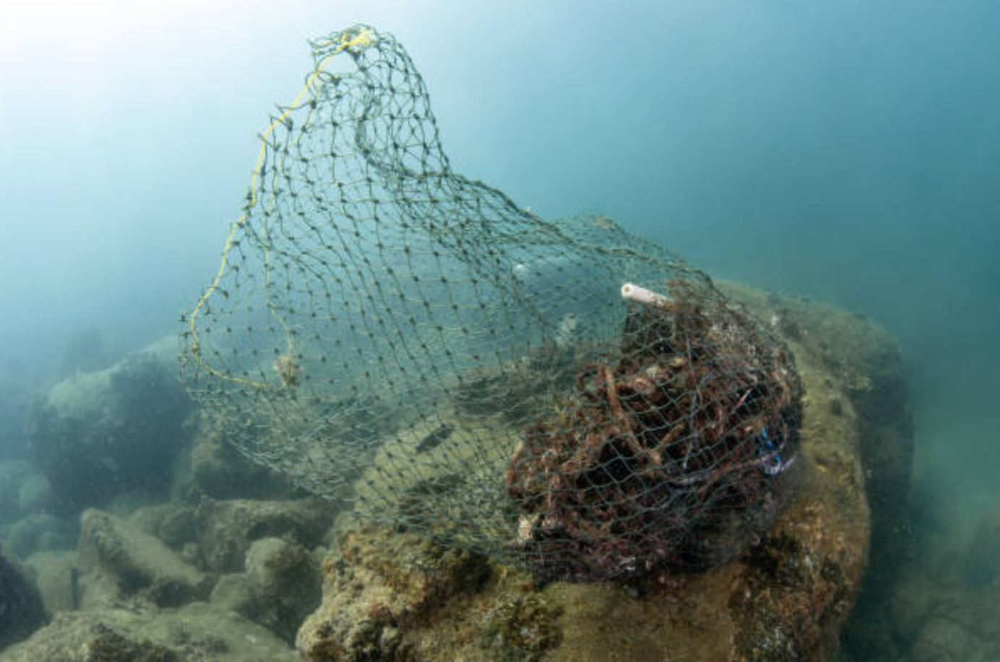

In [ ]:
# Upload an image for a qualitative single-frame review.
from google.colab import files
from IPython.display import display
from PIL import Image

uploaded = files.upload()

image_path = next(iter(uploaded))

display(Image.open(image_path))


image 1/1 /content/Screenshot 2026-11-23 173623.png: 448x640 1 Net, 195.3ms
Speed: 10.3ms preprocess, 195.3ms inference, 15.2ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/drive/MyDrive/MarineGuard_Inference/test_images


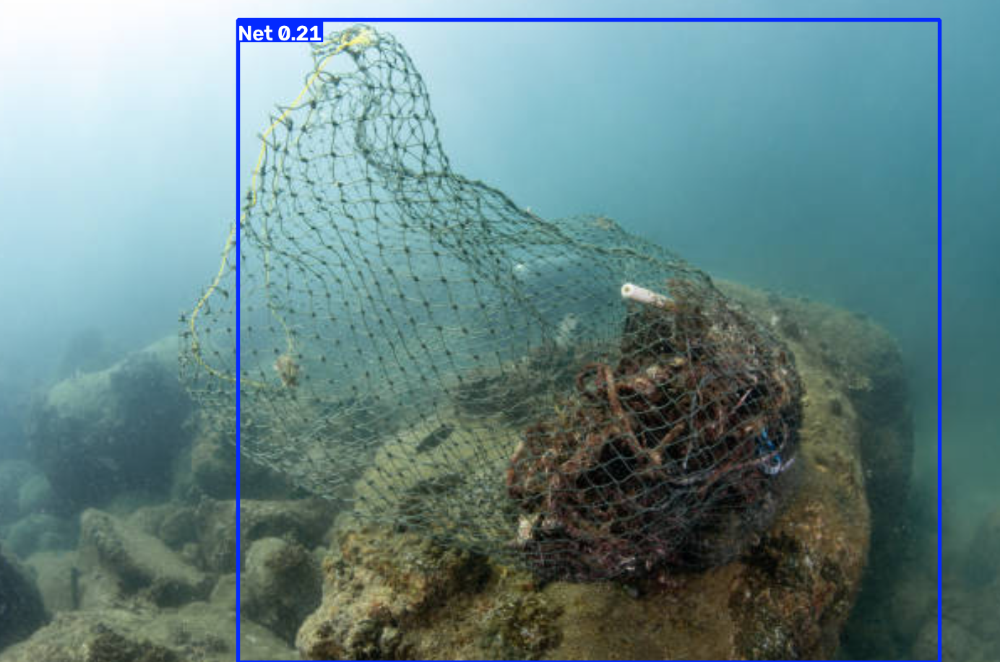

In [ ]:
# Run 640 px inference and save the annotated prediction.
from IPython.display import display
from PIL import Image

results = model.predict(
    source=image_path,
    conf=0.15,
    imgsz=640,
    device="cpu",
    save=True,
    project="/content/drive/MyDrive/MarineGuard_Inference",
    name="test_images",
    exist_ok=True
)

display(Image.fromarray(results[0].plot()[..., ::-1]))

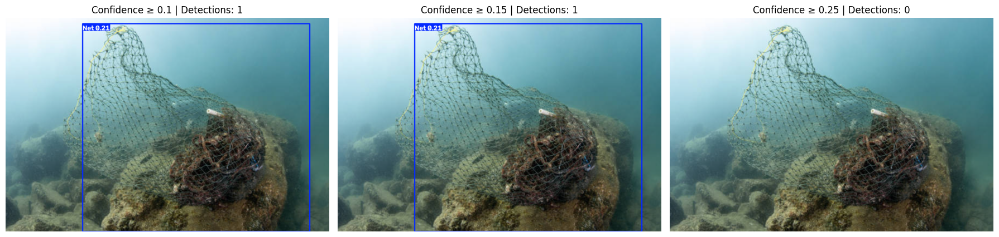

In [ ]:
# Compare detection counts and annotations across confidence cutoffs.
from IPython.display import display
from PIL import Image
import matplotlib.pyplot as plt

thresholds = [0.10, 0.15, 0.25]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, conf in zip(axes, thresholds):
    result = model.predict(
        source=image_path,
        conf=conf,
        imgsz=640,
        device="cpu",
        verbose=False
    )[0]

    annotated = Image.fromarray(
        result.plot()[..., ::-1]
    )

    ax.imshow(annotated)
    ax.set_title(
        f"Confidence ≥ {conf} | "
        f"Detections: {len(result.boxes)}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

## 4. Qualitative review of 15 uploaded images

Run the selected YOLO26n checkpoint on 15 uploaded images and export the annotated images and detection records. The upload source is not independently verified, and no reference labels are supplied; these examples therefore support qualitative inspection only.

In [ ]:
# Store the 15 uploaded review images separately from the source dataset.
from google.colab import drive, files
from pathlib import Path

drive.mount("/content/drive")

TEST_DIR = Path(
    "/content/drive/MyDrive/MarineGuard_Unseen_Test"
)

TEST_DIR.mkdir(parents=True, exist_ok=True)

print("Upload your 15 underwater images.")

uploaded = files.upload()

for filename, content in uploaded.items():
    (TEST_DIR / filename).write_bytes(content)

print(f"\nSaved {len(uploaded)} images to:")
print(TEST_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Upload your 15 underwater images.


Saving Screenshot 2026-11-23 174626.png to Screenshot 2026-11-23 174626.png
Saving Screenshot 2026-11-23 174619.png to Screenshot 2026-11-23 174619.png
Saving Screenshot 2026-11-23 174607.png to Screenshot 2026-11-23 174607.png
Saving Screenshot 2026-11-23 174554.png to Screenshot 2026-11-23 174554.png
Saving Screenshot 2026-11-23 174520.png to Screenshot 2026-11-23 174520.png
Saving Screenshot 2026-11-23 174505.png to Screenshot 2026-11-23 174505.png
Saving Screenshot 2026-11-23 174446.png to Screenshot 2026-11-23 174446.png
Saving Screenshot 2026-11-23 174438.png to Screenshot 2026-11-23 174438.png
Saving Screenshot 2026-11-23 174431.png to Screenshot 2026-11-23 174431.png
Saving Screenshot 2026-11-23 174346.png to Screenshot 2026-11-23 174346.png
Saving Screenshot 2026-11-23 174332.png to Screenshot 2026-11-23 174332.png
Saving Screenshot 2026-11-23 174149.png to Screenshot 2026-11-23 174149.png
Saving Screenshot 2026-11-23 174117.png to Screenshot 2026-11-23 174117.png
Saving Scree

In [ ]:
# Run YOLO26n inference over the 15-image review set.
from ultralytics import YOLO
from pathlib import Path
import pandas as pd

MODEL_PATH = Path(
    "/content/drive/MyDrive/MarineGuard_Model_Selection/"
    "budget20_30_v1/runs_budget20_30_v1/"
    "final/yolo26n/weights/best.pt"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/MarineGuard_Unseen_Results"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model = YOLO(str(MODEL_PATH))

image_paths = sorted(
    p for p in TEST_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
)

assert len(image_paths) == 15, (
    f"Expected 15 images, found {len(image_paths)}."
)

results = model.predict(
    source=[str(p) for p in image_paths],
    imgsz=640,
    conf=0.10,
    device="cpu",
    save=True,
    project=str(OUTPUT_DIR),
    name="detections",
    exist_ok=True,
    verbose=False
)

print(f"Processed {len(results)} images.")
print("Annotated images saved to:", OUTPUT_DIR / "detections")

Results saved to /content/drive/MyDrive/MarineGuard_Unseen_Results/detections
Processed 15 images.
Annotated images saved to: /content/drive/MyDrive/MarineGuard_Unseen_Results/detections


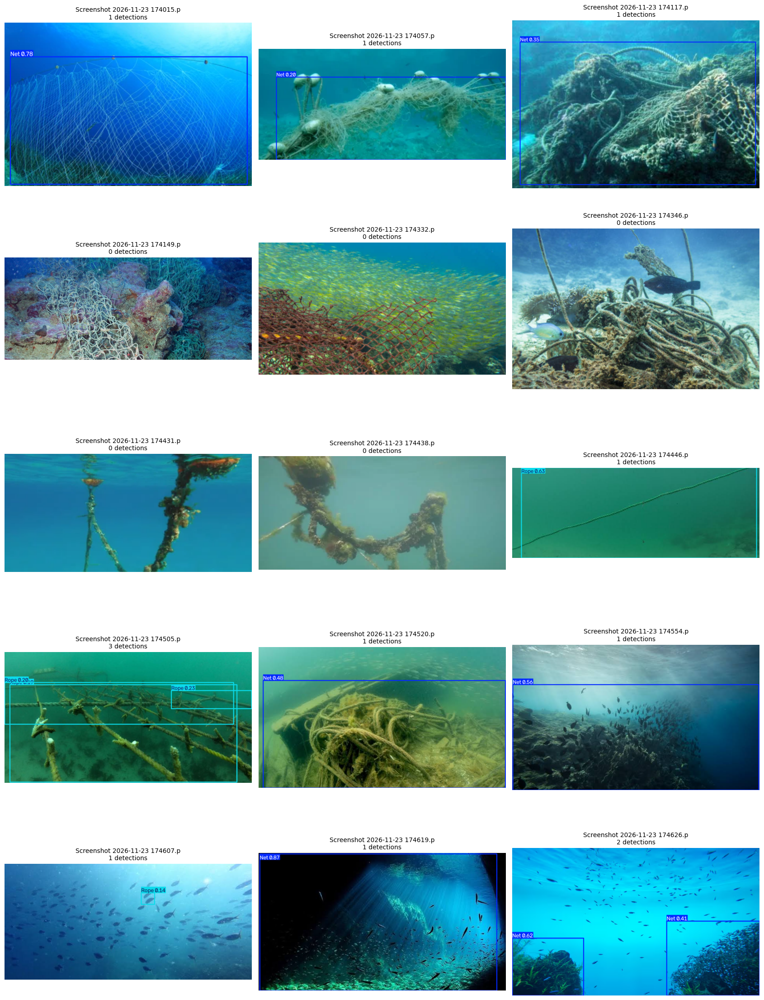

In [ ]:
# Display the saved 15-image prediction grid.
import matplotlib.pyplot as plt
import cv2

fig, axes = plt.subplots(5, 3, figsize=(17, 23))

for ax, result in zip(axes.flat, results):
    annotated = result.plot()
    rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

    ax.imshow(rgb)
    ax.set_title(
        f"{Path(result.path).name[:30]}\n"
        f"{len(result.boxes)} detections",
        fontsize=10
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Export per-detection class, confidence, and image identifiers.
import pandas as pd

records = []

for result in results:
    image_name = Path(result.path).name

    if len(result.boxes) == 0:
        records.append({
            "image": image_name,
            "detected_class": "None",
            "confidence": None,
            "detections": 0
        })
        continue

    for box in result.boxes:
        class_id = int(box.cls.item())
        confidence = float(box.conf.item())

        records.append({
            "image": image_name,
            "detected_class": model.names[class_id],
            "confidence": round(confidence, 4),
            "detections": len(result.boxes)
        })

report = pd.DataFrame(records)

report.to_csv(
    OUTPUT_DIR / "detection_report.csv",
    index=False
)

display(report)

print("Report saved to:")
print(OUTPUT_DIR / "detection_report.csv")

,image,detected_class,confidence,detections
0,Screenshot 2026-11-23 174015.png,Net,0.7830,1
1,Screenshot 2026-11-23 174057.png,Net,0.1982,1
2,Screenshot 2026-11-23 174117.png,Net,0.3545,1
3,Screenshot 2026-11-23 174149.png,None,NaN,0
4,Screenshot 2026-11-23 174332.png,None,NaN,0
5,Screenshot 2026-11-23 174346.png,None,NaN,0
6,Screenshot 2026-11-23 174431.png,None,NaN,0
7,Screenshot 2026-11-23 174438.png,None,NaN,0
8,Screenshot 2026-11-23 174446.png,Rope,0.6338,1
9,Screenshot 2026-11-23 174505.png,Rope,0.2255,3


Report saved to:
/content/drive/MyDrive/MarineGuard_Unseen_Results/detection_report.csv


## 5. Side-by-side comparison: YOLO12n and YOLO26n

Apply both saved finalist checkpoints to the same 15 images with identical inference settings (640 px, confidence 0.10). Compare predicted locations, class labels, missed objects, and false detections visually.

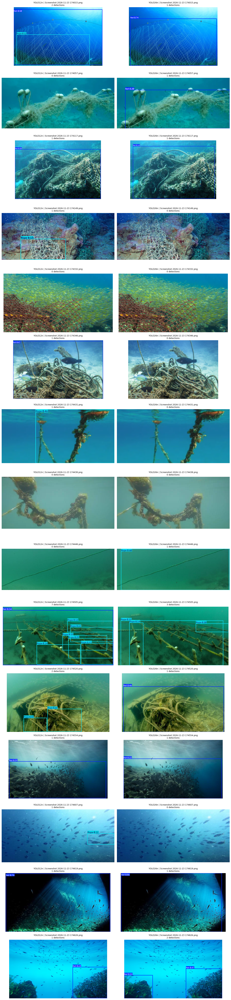

Comparison saved to: /content/drive/MyDrive/MarineGuard_Unseen_Results/yolo12_vs_yolo26.png


In [ ]:
# Compare the saved YOLO12n and YOLO26n finalists on matched images.
from pathlib import Path
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2

BASE = Path(
    "/content/drive/MyDrive/MarineGuard_Model_Selection/"
    "budget20_30_v1/runs_budget20_30_v1/final"
)

TEST_DIR = Path(
    "/content/drive/MyDrive/MarineGuard_Unseen_Test"
)

models = {
    "YOLO12n": YOLO(str(BASE / "yolo12n/weights/best.pt")),
    "YOLO26n": YOLO(str(BASE / "yolo26n/weights/best.pt"))
}

images = sorted(
    p for p in TEST_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
)

assert len(images) == 15, f"Expected 15 images, found {len(images)}"

fig, axes = plt.subplots(
    len(images), 2,
    figsize=(14, 4 * len(images))
)

for col, (name, model) in enumerate(models.items()):
    for row, image in enumerate(images):
        result = model.predict(
            source=str(image),
            conf=0.10,
            imgsz=640,
            device="cpu",
            verbose=False
        )[0]

        annotated = cv2.cvtColor(
            result.plot(), cv2.COLOR_BGR2RGB
        )

        axes[row, col].imshow(annotated)
        axes[row, col].set_title(
            f"{name} | {image.name}\n"
            f"{len(result.boxes)} detections",
            fontsize=9
        )
        axes[row, col].axis("off")

plt.tight_layout()

OUTPUT = Path(
    "/content/drive/MyDrive/MarineGuard_Unseen_Results"
)

OUTPUT.mkdir(parents=True, exist_ok=True)

plt.savefig(
    OUTPUT / "yolo12_vs_yolo26.png",
    dpi=130,
    bbox_inches="tight"
)

plt.show()

print("Comparison saved to:", OUTPUT / "yolo12_vs_yolo26.png")

## 6. In-dataset prediction check

Compare the same finalists on five uploaded images drawn from the prepared dataset. These examples illustrate model behavior on familiar data and must not be interpreted as independent generalization evidence.

In [ ]:
# Stage five dataset images for a qualitative sanity check.
from google.colab import files
from pathlib import Path

uploaded = files.upload()

TEST_DIR = Path("/content/marineguard_5_images")
TEST_DIR.mkdir(exist_ok=True)

for filename, content in uploaded.items():
    (TEST_DIR / filename).write_bytes(content)

images = sorted(
    p for p in TEST_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
)

assert len(images) == 5, f"Expected 5 images, found {len(images)}"

print("Ready:", len(images), "images")

Saving Screenshot 2026-11-23 180123.png to Screenshot 2026-11-23 180123.png
Saving Screenshot 2026-11-23 180115.png to Screenshot 2026-11-23 180115.png
Saving Screenshot 2026-11-23 180055.png to Screenshot 2026-11-23 180055.png
Saving Screenshot 2026-11-23 180043.png to Screenshot 2026-11-23 180043.png
Saving Screenshot 2026-11-23 180034.png to Screenshot 2026-11-23 180034.png
Ready: 5 images


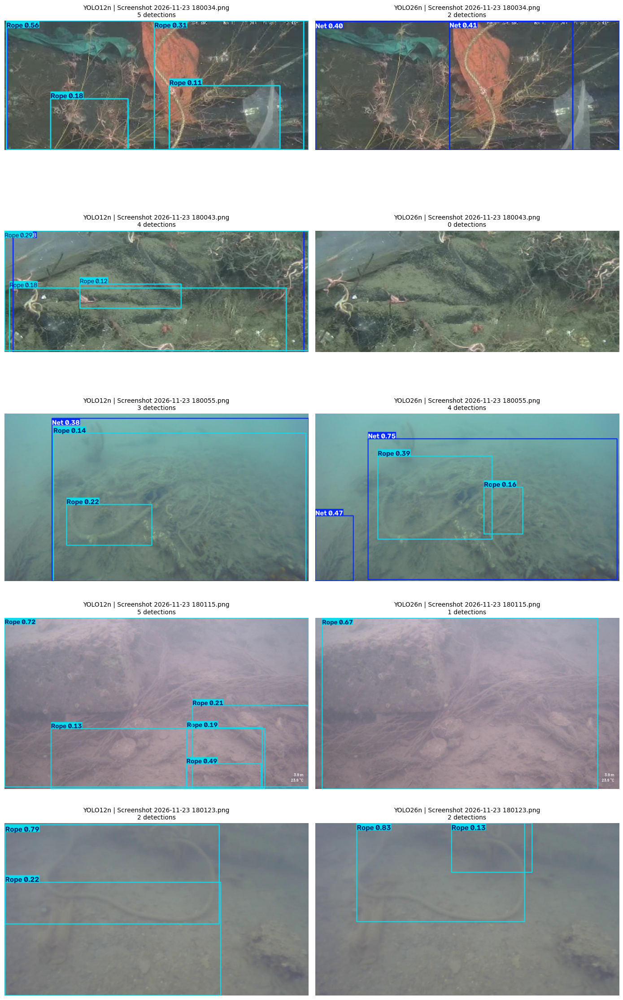

In [ ]:
# Display matched predictions for both finalists.
from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt
import cv2

BASE = Path(
    "/content/drive/MyDrive/MarineGuard_Model_Selection/"
    "budget20_30_v1/runs_budget20_30_v1/final"
)

models = {
    "YOLO12n": YOLO(str(BASE / "yolo12n/weights/best.pt")),
    "YOLO26n": YOLO(str(BASE / "yolo26n/weights/best.pt"))
}

fig, axes = plt.subplots(5, 2, figsize=(14, 23))

for col, (name, model) in enumerate(models.items()):
    for row, img in enumerate(images):

        result = model.predict(
            source=str(img),
            conf=0.10,
            imgsz=640,
            device="cpu",
            verbose=False
        )[0]

        annotated = cv2.cvtColor(
            result.plot(), cv2.COLOR_BGR2RGB
        )

        axes[row, col].imshow(annotated)
        axes[row, col].set_title(
            f"{name} | {img.name}\n"
            f"{len(result.boxes)} detections",
            fontsize=10
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Save the five-image finalist comparison figure.
OUTPUT = Path(
    "/content/drive/MyDrive/MarineGuard_Inference/"
    "dataset_5_comparison"
)

OUTPUT.mkdir(parents=True, exist_ok=True)

fig.savefig(
    OUTPUT / "yolo12_vs_yolo26.png",
    dpi=150,
    bbox_inches="tight"
)

print("Saved to:", OUTPUT)

Saved to: /content/drive/MyDrive/MarineGuard_Inference/dataset_5_comparison


## 7. Original YOLO26n training history

Read the recorded `results.csv` from the original finalist run and plot validation mAP50 and mAP50–95 by epoch. The run recorded 21 epochs; the variation in validation performance motivates checking the saved best checkpoint rather than relying on the last epoch.

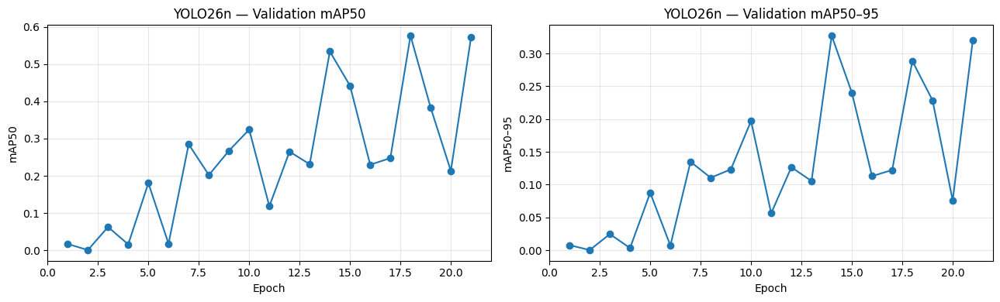


Last 10 epochs:


,epoch,metrics/mAP50(B),metrics/mAP50-95(B)
11,12,0.26489,0.12651
12,13,0.23108,0.10548
13,14,0.53362,0.32701
14,15,0.44180,0.24025
15,16,0.22972,0.11292
16,17,0.24751,0.12226
17,18,0.57586,0.28844
18,19,0.38274,0.22859
19,20,0.21321,0.07602
20,21,0.57148,0.32060


In [ ]:
# Plot validation metrics from the recorded finalist training run.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

csv_path = Path(
    "/content/drive/MyDrive/MarineGuard_Model_Selection/"
    "budget20_30_v1/runs_budget20_30_v1/"
    "final/yolo26n/results.csv"
)

df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    df["epoch"],
    df["metrics/mAP50(B)"],
    marker="o"
)
axes[0].set_title("YOLO26n — Validation mAP50")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("mAP50")
axes[0].grid(alpha=0.3)

axes[1].plot(
    df["epoch"],
    df["metrics/mAP50-95(B)"],
    marker="o"
)
axes[1].set_title("YOLO26n — Validation mAP50–95")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("mAP50–95")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\nLast 10 epochs:")
display(
    df[
        ["epoch", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]
    ].tail(10)
)

## 8. Input resolution: visual comparison

Inspect predictions from the same YOLO26n checkpoint at 640 px and 960 px on the five uploaded images. The next section evaluates these settings quantitatively on the full original validation split.

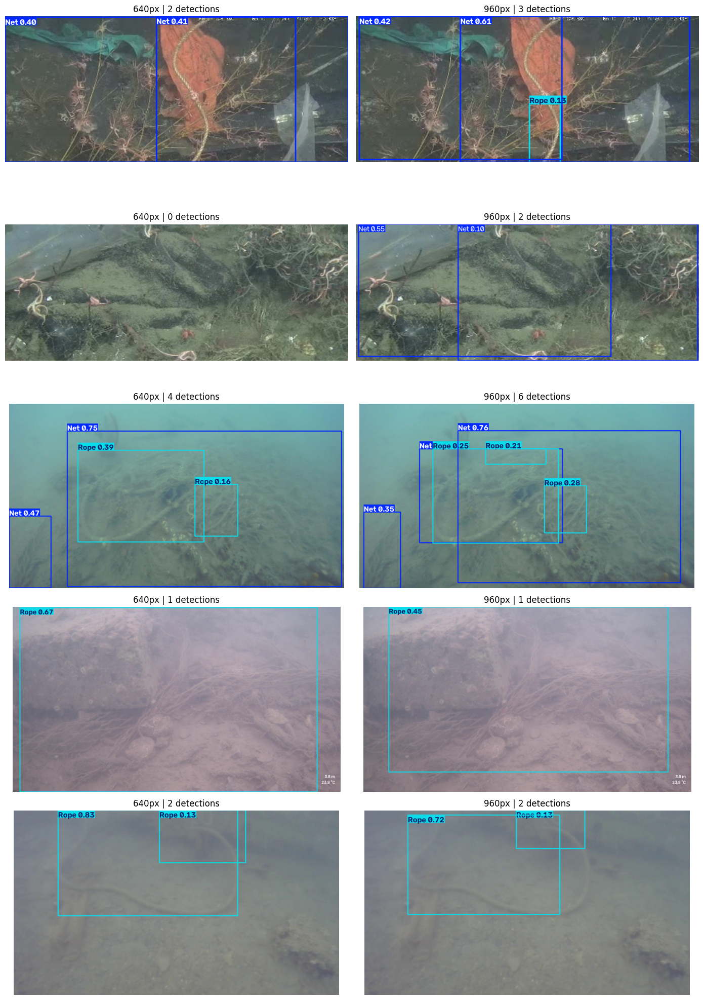

In [ ]:
# Compare 640 px and 960 px predictions on the same images.
from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt
import cv2

MODEL_PATH = (
    "/content/drive/MyDrive/MarineGuard_Model_Selection/"
    "budget20_30_v1/runs_budget20_30_v1/"
    "final/yolo26n/weights/best.pt"
)

model = YOLO(MODEL_PATH)

sizes = [640, 960]

fig, axes = plt.subplots(
    len(images), 2,
    figsize=(14, 4 * len(images)),
    squeeze=False
)

for row, img in enumerate(images):
    for col, size in enumerate(sizes):

        result = model.predict(
            source=str(img),
            imgsz=size,
            conf=0.10,
            device="cpu",
            verbose=False
        )[0]

        annotated = cv2.cvtColor(
            result.plot(), cv2.COLOR_BGR2RGB
        )

        axes[row, col].imshow(annotated)
        axes[row, col].set_title(
            f"{size}px | {len(result.boxes)} detections"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## 9. Input resolution: validation metrics

Run the original validation set at both resolutions without retraining. The saved results favor **640 px**: mAP50–95 is **0.3271** at 640 px versus **0.1116** at 960 px. We therefore retain 640 px for subsequent inference.

In [ ]:
# Evaluate the original validation set at both inference resolutions.
from ultralytics import YOLO
from pathlib import Path
import pandas as pd

MODEL_PATH = (
    "/content/drive/MyDrive/MarineGuard_Model_Selection/"
    "budget20_30_v1/runs_budget20_30_v1/"
    "final/yolo26n/weights/best.pt"
)

DATA = (
    "/content/drive/MyDrive/MarineGuard_YOLO/"
    "MarineGuard_YOLO_Fixed/data.yaml"
)

model = YOLO(MODEL_PATH)
rows = []

for size in [640, 960]:
    print(f"\nEvaluating YOLO26n at {size}px...")

    metrics = model.val(
        data=DATA,
        split="val",
        imgsz=size,
        batch=4,
        device="cpu",
        workers=0,
        plots=False,
        verbose=False
    )

    row = {
        "imgsz": size,
        "mAP50": float(metrics.box.map50),
        "mAP50-95": float(metrics.box.map),
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "net_mAP50-95": float(metrics.box.maps[0]),
        "rope_mAP50-95": float(metrics.box.maps[1])
    }

    rows.append(row)

comparison = pd.DataFrame(rows)
display(comparison)

OUT = Path(
    "/content/drive/MyDrive/MarineGuard_Inference/"
    "inference_optimization"
)
OUT.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    OUT / "resolution_comparison.csv",
    index=False
)

print("Saved:", OUT / "resolution_comparison.csv")


Evaluating YOLO26n at 640px...
Ultralytics 8.4.216 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (AMD EPYC 7B12)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 1.2±1.7 ms, read: 18.0±39.7 MB/s, size: 198.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed/labels/val.cache... 178 images, 100 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 178/178 35.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 1.9it/s 23.6s
                   all        178         78      0.697      0.667      0.533      0.327
Speed: 0.5ms preprocess, 62.6ms inference, 0.0ms loss, 0.3ms postprocess per image

Evaluating YOLO26n at 960px...
Ultralytics 8.4.216 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (AMD E

,imgsz,mAP50,mAP50-95,precision,recall,net_mAP50-95,rope_mAP50-95
0,640,0.533364,0.327078,0.697227,0.667462,0.299444,0.354711
1,960,0.245809,0.111597,0.224633,0.253521,0.026026,0.197169


Saved: /content/drive/MyDrive/MarineGuard_Inference/inference_optimization/resolution_comparison.csv


## 10. Confidence-threshold analysis

Review the previously exported class-specific confidence sweep and F1 results. The original validation set favors 0.25 for Net and 0.15 for Rope under the chosen matching criterion. These thresholds are **validation-derived deployment settings**, not changes to the trained model or proof of cross-domain reliability.

In [ ]:
# Read the saved per-class confidence sweep and F1 selections.
from pathlib import Path
import pandas as pd

OUT = Path(
    "/content/drive/MyDrive/MarineGuard_Model_Selection/"
    "budget20_30_v1"
)

sweep_path = OUT / "threshold_sweep.csv"
best_path = OUT / "best_thresholds.csv"

assert sweep_path.exists(), "threshold_sweep.csv not found"

sweep = pd.read_csv(sweep_path)
print("Threshold analysis columns:")
print(sweep.columns.tolist())

print("\nYOLO26n threshold results:")
display(
    sweep[
        sweep["model"].astype(str).str.lower() == "yolo26n"
    ].round(3)
)

if best_path.exists():
    best = pd.read_csv(best_path)
    print("\nBest F1 thresholds:")
    display(best[best["model"].astype(str).str.lower() == "yolo26n"])


Threshold analysis columns:
['model', 'threshold', 'class', 'TP', 'FP', 'FN', 'precision', 'recall', 'f1', 'negative_fp', 'inference_seconds']

YOLO26n threshold results:


,model,threshold,class,TP,FP,FN,precision,recall,f1,negative_fp,inference_seconds
16,yolo26n,0.05,Net,6,33,1,0.154,0.857,0.261,2,14.033
17,yolo26n,0.05,Rope,52,92,19,0.361,0.732,0.484,26,14.033
18,yolo26n,0.10,Net,6,21,1,0.222,0.857,0.353,0,14.033
19,yolo26n,0.10,Rope,47,37,24,0.560,0.662,0.606,6,14.033
20,yolo26n,0.15,Net,6,14,1,0.300,0.857,0.444,0,14.033
21,yolo26n,0.15,Rope,42,23,29,0.646,0.592,0.618,3,14.033
22,yolo26n,0.20,Net,6,9,1,0.400,0.857,0.545,0,14.033
23,yolo26n,0.20,Rope,38,18,33,0.679,0.535,0.598,3,14.033
24,yolo26n,0.25,Net,6,8,1,0.429,0.857,0.571,0,14.033
25,yolo26n,0.25,Rope,36,10,35,0.783,0.507,0.615,3,14.033



Best F1 thresholds:


,model,threshold,class,TP,FP,FN,precision,recall,f1,negative_fp,inference_seconds
1,yolo26n,0.25,Net,6,8,1,0.428571,0.857143,0.571429,0,14.033152
3,yolo26n,0.15,Rope,42,23,29,0.646154,0.591549,0.617647,3,14.033152


## 11. Class-specific confidence filtering

Apply the selected Net (0.25) and Rope (0.15) thresholds to the five-image demonstration after prediction at confidence 0.10. This filters reported detections without altering checkpoint weights.

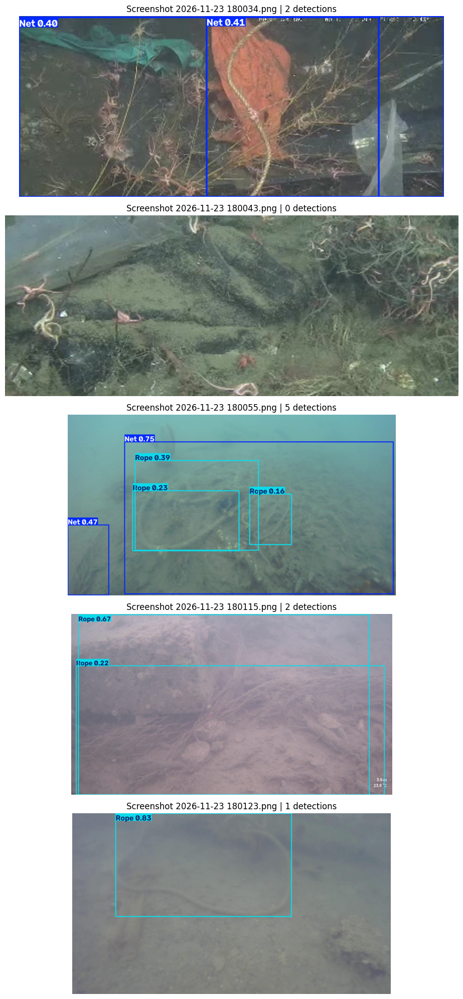

In [ ]:
# Apply validation-derived class-specific thresholds during inference.
from pathlib import Path
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2

MODEL_PATH = Path(
    "/content/drive/MyDrive/MarineGuard_Model_Selection/"
    "budget20_30_v1/runs_budget20_30_v1/"
    "final/yolo26n/weights/best.pt"
)

model = YOLO(str(MODEL_PATH))

CLASS_THRESHOLDS = {
    0: 0.25,  # Net
    1: 0.15   # Rope
}

def detect_fishing_gear(image):
    result = model.predict(
        source=str(image),
        imgsz=640,
        conf=0.10,
        iou=0.70,
        device="cpu",
        verbose=False
    )[0]

    boxes = result.boxes
    if boxes is not None and len(boxes):
        keep = [
            i for i, (cls, conf) in enumerate(
                zip(boxes.cls.tolist(), boxes.conf.tolist())
            )
            if conf >= CLASS_THRESHOLDS[int(cls)]
        ]
        result.boxes = boxes[keep]

    return result

# Reuse the five uploaded images
fig, axes = plt.subplots(
    len(images), 1,
    figsize=(10, 4 * len(images)),
    squeeze=False
)

for row, img in enumerate(images):
    result = detect_fishing_gear(img)
    annotated = cv2.cvtColor(
        result.plot(), cv2.COLOR_BGR2RGB
    )

    axes[row, 0].imshow(annotated)
    axes[row, 0].set_title(
        f"{img.name} | {len(result.boxes)} detections"
    )
    axes[row, 0].axis("off")

plt.tight_layout()
plt.show()


## 12. External evaluation: TrashCan

Evaluate the original YOLO26n on the 214-image TrashCan test split, which was not used for training. The saved result is **mAP50–95 = 0.00175** (approximately 0.18%), indicating very weak generalization to this external image distribution. These results are retained as an important model limitation rather than omitted from the report.

In [6]:
# Evaluate the original checkpoint on the external TrashCan test split.

%pip install -q ultralytics
from ultralytics import YOLO
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed")
DATA_YAML = ROOT / "data.yaml"

BASE = Path("/content/drive/MyDrive/MarineGuard_Model_Selection/budget20_30_v1")

CHECKPOINT = (
    BASE / "runs_budget20_30_v1"
    / "final/yolo26n/weights/best.pt"
)

assert CHECKPOINT.is_file(), f"Missing checkpoint: {CHECKPOINT}"

model = YOLO(str(CHECKPOINT))

# Independent test evaluation — no training
test_results = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    device="cpu",
    batch=4,
    workers=0,
    conf=0.001,
    plots=True,
    project=str(BASE / "external_test"),
    name="yolo26n_640",
    exist_ok=True
)

report = pd.DataFrame([{
    "Dataset": "TrashCan External Test",
    "mAP50": float(test_results.box.map50),
    "mAP50-95": float(test_results.box.map),
    "Precision": float(test_results.box.mp),
    "Recall": float(test_results.box.mr),
    "Net mAP50-95": float(test_results.box.maps[0]),
    "Rope mAP50-95": float(test_results.box.maps[1])
}])

display(report.round(4))

output = BASE / "external_test" / "external_test_results.csv"
report.to_csv(output, index=False)

print("\nSaved:", output)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 1.8±2.1 ms, read: 2.6±5.8 MB/s, size: 30.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed/labels/test... 214 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 214/214 175.7it/s 1.2s
val: New cache created: /content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed/labels/test.cache
                 Class     Ima

,Dataset,mAP50,mAP50-95,Precision,Recall,Net mAP50-95,Rope mAP50-95
0,TrashCan External Test,0.0051,0.0018,0.0159,0.0411,0.0014,0.0021



Saved: /content/drive/MyDrive/MarineGuard_Model_Selection/budget20_30_v1/external_test/external_test_results.csv


## 13. External error analysis

Inspect six reproducibly sampled TrashCan images with ground-truth boxes alongside predicted boxes. Use the visual comparison to identify missed objects, oversized detections, and class confusion. This is diagnostic evidence alongside the quantitative external-test metrics.

Model classes: {0: 'Net', 1: 'Rope'}


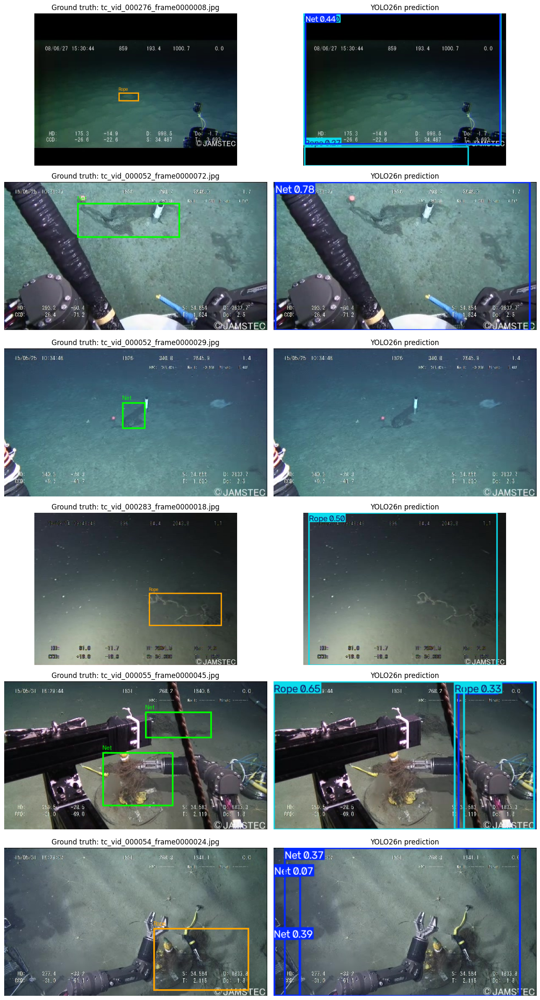

In [7]:
# Compare a reproducible sample of external ground-truth labels and predictions.

from pathlib import Path
from ultralytics import YOLO
from PIL import Image, ImageDraw
from IPython.display import display
import matplotlib.pyplot as plt
import random

ROOT = Path("/content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed")
BASE = Path("/content/drive/MyDrive/MarineGuard_Model_Selection/budget20_30_v1")

CHECKPOINT = (
    BASE / "runs_budget20_30_v1"
    / "final/yolo26n/weights/best.pt"
)

model = YOLO(str(CHECKPOINT))
print("Model classes:", model.names)

image_dir = ROOT / "images/test"
label_dir = ROOT / "labels/test"

images = sorted([
    p for p in image_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
])

random.seed(42)
samples = random.sample(images, min(6, len(images)))

colors = ["lime", "orange"]
names = ["Net", "Rope"]

fig, axes = plt.subplots(len(samples), 2,
                         figsize=(13, 4 * len(samples)),
                         squeeze=False)

for i, image_path in enumerate(samples):
    original = Image.open(image_path).convert("RGB")
    width, height = original.size

    # Ground truth
    gt = original.copy()
    draw = ImageDraw.Draw(gt)

    label_path = label_dir / (image_path.stem + ".txt")

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue

            cls = int(parts[0])
            xc, yc, bw, bh = map(float, parts[1:])

            x1 = (xc - bw / 2) * width
            y1 = (yc - bh / 2) * height
            x2 = (xc + bw / 2) * width
            y2 = (yc + bh / 2) * height

            draw.rectangle(
                [x1, y1, x2, y2],
                outline=colors[cls],
                width=3
            )
            draw.text(
                (x1, max(0, y1 - 14)),
                names[cls],
                fill=colors[cls]
            )

    # Model predictions (diagnostic visualization only)
    prediction = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.05,
        device="cpu",
        verbose=False
    )[0]

    pred = Image.fromarray(
        prediction.plot()[..., ::-1]
    )

    axes[i, 0].imshow(gt)
    axes[i, 0].set_title(f"Ground truth: {image_path.name}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(pred)
    axes[i, 1].set_title("YOLO26n prediction")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


## 14. Original validation sanity check

Confirm that the selected checkpoint reproduces the recorded original-validation performance at 640 px. This consistency check does not create an additional independent evaluation set.

In [8]:
# Recompute the original validation metrics as a checkpoint sanity check.
from ultralytics import YOLO
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed")
BASE = Path("/content/drive/MyDrive/MarineGuard_Model_Selection/budget20_30_v1")

CHECKPOINT = (
    BASE / "runs_budget20_30_v1"
    / "final/yolo26n/weights/best.pt"
)

model = YOLO(str(CHECKPOINT))

print("Loaded checkpoint:", CHECKPOINT)
print("Model classes:", model.names)

val_check = model.val(
    data=str(ROOT / "data.yaml"),
    split="val",
    imgsz=640,
    device="cpu",
    batch=4,
    workers=0,
    conf=0.001,
    plots=False,
    project=str(BASE / "diagnostics"),
    name="validation_sanity_check",
    exist_ok=True
)

print("\n--- VALIDATION SANITY CHECK ---")
print(f"mAP50:      {val_check.box.map50:.4f}")
print(f"mAP50-95:   {val_check.box.map:.4f}")
print(f"Precision:  {val_check.box.mp:.4f}")
print(f"Recall:     {val_check.box.mr:.4f}")
print(f"Net mAP:    {val_check.box.maps[0]:.4f}")
print(f"Rope mAP:   {val_check.box.maps[1]:.4f}")

Loaded checkpoint: /content/drive/MyDrive/MarineGuard_Model_Selection/budget20_30_v1/runs_budget20_30_v1/final/yolo26n/weights/best.pt
Model classes: {0: 'Net', 1: 'Rope'}
Ultralytics 8.4.216 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 2.9±3.9 ms, read: 30.0±40.6 MB/s, size: 156.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed/labels/val.cache... 178 images, 100 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 178/178 41.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 2.3it/s 19.6s
                   all        178         78      0.697      0.667      0.533      0.327
                   Net      

## Evaluation summary

- **Selected artifact:** original YOLO26n finalist checkpoint (`best.pt`); no retraining in this notebook.
- **Original validation (178 images):** mAP50 **0.5334**, mAP50–95 **0.3271**; results should be interpreted with caution because only seven Net instances appear in this split.
- **Inference resolution:** retain **640 px** based on the recorded validation comparison.
- **Confidence filtering:** Net **0.25** and Rope **0.15** are provisional, validation-derived settings.
- **External TrashCan test (214 images):** mAP50–95 **0.00175**, showing that performance on a different underwater dataset remains a major limitation.

**Version 1 implication.** The original checkpoint can be used for a bounded research prototype and image-level demonstrations; results require human verification and must not be presented as reliable detection across underwater environments.